<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV8_Hlubok%C3%A9_neuronov%C3%A9_s%C3%ADt%C4%9B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 8. -  Hluboké neuronové sítě
---
V tomto cvičení si ukážeme práci s hlubokými neuronovými sítěmi 🧠 Jedná se velice rozsáhlé téma, takže budeme pracovat pouze s určitým druhem síťí: **konvolučními** (**CNN**), v druhé části cvičení si poté předvedeme sílu přeneseného učení v praxi.






# 🛑 Než začneme
- změňte si typ běhového prostředí na **T4 GPU**
- lze to udělat vprovo nahoře v indikátorů zatížení prostředí -> `šipka dolů` -> `Změnit typ běhového prostředí ` -> `T4 GPU` -> `Uložit`
- díky tomu budeme moct pro trénování CNN využívat sílu GPU, což nám ušetří 10-ti násobek času

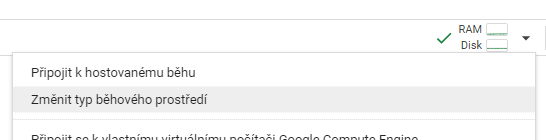

# 🧩 Konvoluční neuronové sitě (CNN)
- Jsou specializované pro **zpracování dat s mřížkovou topologií**, jako jsou **obrázky**.
- Efektivní v pochopení **hierarchie ve vizuálních datech** díky schopnosti zachytit prostorové a temporální závislosti.
- Obsahují **konvoluční vrstvy**, které **aplikují filtry** pro detekci lokálních vzorů - ***DESTILACE PŘÍZNAKŮ*** ⚗
- Po konvolučních vrstvách obvykle následují **pooling vrstvy**, které snižují dimenzionalitu dat - snižují průtok informací - *projdou pouze ty důležité*. 🟢🔴
- Na CNN lze **připojit** například **klasifikátor**, složený z hustě propojených klasických vrstev. 🔗
---
*Nejčastější využití:*
- **klasifikace a detekce** objektů v obraze 🖼
- zpracování přirozeného jazyka





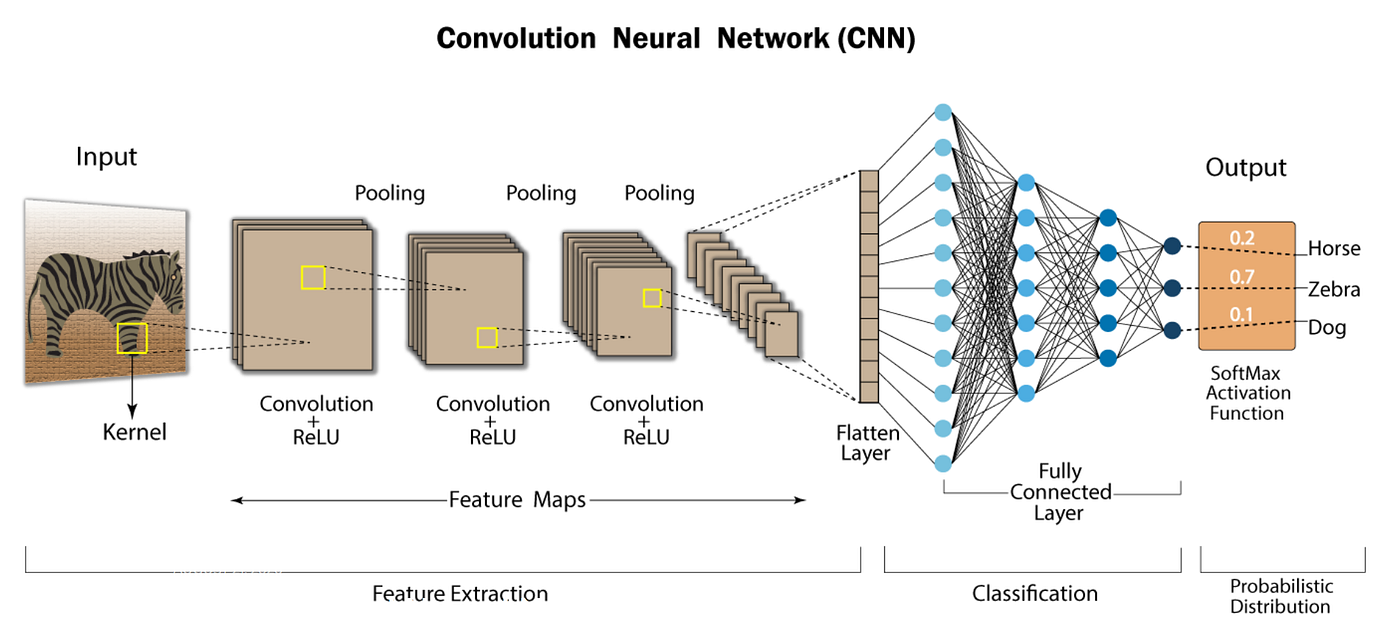

In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Knihovny TensorFlow pro práci s neuronovými sítěmi
import tensorflow as tf

#Knihovny pro práci s OS a časem
import datetime, os

In [ ]:
# Definice funkce která převádí pole na obrázek
from PIL import Image

def arr_to_bmp(array_data, mode="RGB", size=(64,64)):
  img = Image.fromarray(array_data, mode).resize(size)
  return img

## 📃 ČÁST 1: Příprava dat: CIFAR-10
---
Jak už bylo řešeno, použijeme obrazový dataset určený pro klasifikaci - **CIFAR-10** (CIFAR stojí za "*Canadian Institute for Advanced Research*"). Jedná se balík rlzných obrázků z 10 tříd (pes, auto, kočka..)  a hodí se pro experimenty s klasifikačnímy modely.

### Popis datasetu:
*CIFAR-10 je jeden z populárních datasetů používaných v oblasti počítačového vidění a strojového učení. Tento dataset byl vytvořen pro účely trénování a testování algoritmů pro klasifikaci obrázků. Trénovací množina obsahuje 50 000 **barevných obrázků o rozměrech 32x32 pixelů**, rozdělených **do 10 tříd** (5 000 obrázků na třídu).
Testovací množina obsahuje 10 000 obrázků pro vyhodnocení výkonu modelu.*

**Sloupce:**
- Images: bitmapa obrázku 32x32 v RGB formátu (3 kanály / pixel)
- Labels: numerické vyjádření třídy obrázku - třídy lze namapovat na názvy

**Třídy:**
- 0: Letadlo
- 1: Automobil
- 2: Pták
- 3: Kočka
- 4: Jelen
- 5: Pes
- 6: Žába
- 7: Kůň
- 8: Loď
- 9: Nákladní auto

**Cíl:**
CIFAR-10 je často využíván pro vyhodnocování a porovnávání výkonu různých modelů v oblasti klasifikace obrazů.

In [ ]:
#Rychlý náhled dat
# Náhled dat - vizualizace (prvních 10)
def show_img_preview(images, labels, map_func = None, map:dict = None, n=16):
  for i in range(n):
      plt.subplot(int(n/4), int(n/4), i+1)
      plt.imshow(images[i])
      if map_func:
        plt.title(f'{map_func(labels[i], map)}')
      else:
        plt.title(f'{labels[i]}')
      plt.axis('off')

  # Zarovná layout
  plt.tight_layout()

In [ ]:
def index_to_class(index:int, map:dict):
  class_name = "?"
  if int(index) in map:
    class_name = map[index]

  return class_name

In [ ]:
# Import CIFAR-10 datasetu
import tensorflow as tf
cifar10 = tf.keras.datasets.cifar10

# Načtení CIFAR-10 dataset
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
# Slovník pro překlad - mapa, píše se ve tvaru key:value
cifar10_class_dict = {0:"Letadlo", 1:"Automobil", 2: "Pták", 3: "Kočka", 4: "Jelen", 5: "Pes", 6: "Žába", 7: "Kůň", 8: "Loď", 9: "Nákladní auto"}

✍ *Vsuvka:* Pokud si vzpomenete, tak tento dataset byl velmi obtížný pro zpracování a klasifikaci pomocí *běžné neuronové sítě* - Dense network. I ty nejlepší sítě tu dosahují přesnosti okolo 70 %. 📊

### 🔭 Explorační analýza
*Není třeba provádět důkladnou analýzu, jedná se o čistý dataset.*

In [ ]:
# Zkontrolujeme shape a počet dat
train_images.shape, train_images.ndim, test_images.shape, test_images.ndim

((50000, 32, 32, 3), 4, (10000, 32, 32, 3), 4)

✍ *Vsuvka:* Všimnite si tvaru vstupních dat - `train_images`. Mají tvar `(50000, 32, 32, 3)`, což značí 50000 obrázků, 32 pixelů / řádek, 32 pixelů / sloupec a 3 kanály na pixel (RGB).

In [ ]:
train_labels.shape, test_labels.shape

((50000, 1), (10000, 1))

### 👁️ Náhled dat

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]], dtype=uint8)
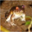

In [ ]:
train_images[0]

/tmp/ipython-input-2284591411.py:5: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(array_data, mode).resize(size)


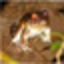

In [ ]:
arr_to_bmp(train_images[0])

In [ ]:
train_labels[0]

array([6], dtype=uint8)

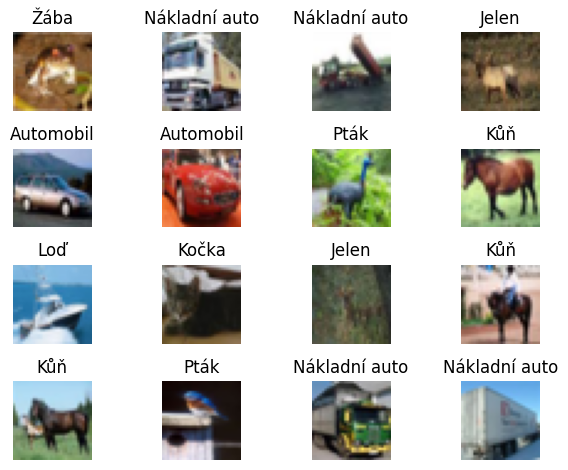

In [ ]:
show_img_preview(train_images, train_labels.reshape(-1), index_to_class, cifar10_class_dict)

## ✂️ Rozdělení, úprava a normalizace dat
Postupujeme stejně jako v předchozím cvičením. Trénovací a testovací množiny ukládáme do `X_train`, `X_test`, `y_train` a `y_test`.

In [ ]:
X_train = train_images
X_test = test_images

y_train = train_labels
y_test = test_labels

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((50000, 32, 32, 3), (10000, 32, 32, 3), (50000, 1), (10000, 1))

### Normalizace dat

In [ ]:
X_train, X_test = X_train/255.0, X_test/255.0

✍ *Vsuvka:* Zde je min 0, tedy ho lze vynechat a prostě vydělit dataset maximem - 255. ➗

✍ *Vsuvka:* Pro konvoluční sítě není nutné ubírat dimenzi ❗

### Validační data
Validační data se používají k on-run ověřování výkonnosti a přesnosti modelu při trénování. Validační data vytvoříme z testovacích dat.

In [ ]:
from sklearn.model_selection import train_test_split

X_test, X_val, y_test, y_val =  train_test_split(X_test, y_test, test_size=0.2)
X_test.shape, y_test.shape, X_val.shape, y_val.shape

((8000, 32, 32, 3), (8000, 1), (2000, 32, 32, 3), (2000, 1))

# Vytvoření modelů
Dataset je připraven, nyní nám stačí vytvořit, natrénovat a otestovat model.  

In [ ]:
# Zobraz historii jako graf
def show_history(history, ignore_val = True):
    plt.figure()
    for key in history.history.keys():
      if key.find("val") != -1 and ignore_val:
        continue

      style = "-" if key.find("val") == -1 else "--"
      plt.plot(history.epoch, history.history[key], label=key, linestyle=style)
    plt.legend()
    plt.tight_layout()

In [ ]:
# Funkce pro převod mezi distribucí pravděpodobnosti a číslem třídy
def prob_to_class(p):
  c =  np.argmax(p)
  return c

def probs_to_classes(probs):
  classes = []
  for p in probs:
    c =  prob_to_class(p)
    classes.append(c)

  return np.array(classes)

## ⭐  Model 1: Konvoluční síť s klasifikátorem

## 🤔 Strategie:
- **Cíl:** klasifikovat obrázky do tříd
- potřebujeme problém rozdělit na dvě hlavní části - **destilace příznaků** z obrázků a **klasifikace do tříd** na základě těchto příznaků
- pro destilaci příznaků použijeme konvoluční část sítě
- jako klasifikátor pak klasikou hustě propojenou (Dense) část sítě
- tedy: **tělo** - konvoluční=destilace přiznaků, **hlava** - hustě propojená=klasifikátor

## 🗼 Architektura:
**Vstupní vrstva:**
- Přijímá obrázky s rozměry 32x32x3 (výška x šířka x barevné kanály).

**Konvoluční část:**

- Konvoluční vrstva s 16 filtry o velikosti 3x3 a `ReLU` aktivační funkcí.
- Max Pooling vrstva s oknem 2x2 pro snížení dimenze.

- Konvoluční vrstva s 32 filtry o velikosti 3x3 a `ReLU` aktivační funkcí.
- Max Pooling vrstva s oknem 2x2.


**Klasifikátor:**

- Hustě propojená vrstva (`Dense`) s 256 neurony a ReLU aktivační funkcí.
- Dropout vrstva s pravděpodobností zahození 50% pro redukci přeučení.

**Výstupní vrstva:**
- Hustě propojená vrstva (`Dense`) s 10 neurony (pro 10 tříd CIFAR-10) s `softmax` aktivační funkcí, která poskytne pravděpodobnostní distribuci jednotlivých tříd.

In [ ]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Model

# Definice vstupní vrstvy
inputs = Input(shape=(32, 32, 3))

# První konvoluční blok
x = Conv2D(16, (3, 3), activation='relu')(inputs)
x = MaxPooling2D((2, 2))(x)

# Druhý konvoluční blok
x = Conv2D(32, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)

# Flatten vrstva
x = Flatten()(x)

# Plně propojená vrstva
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

# Výstupní vrstva
outputs = Dense(10, activation='softmax')(x)

# Vytvoření modelu
model = Model(inputs=inputs, outputs=outputs)

In [ ]:
# Kompilace modelu
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Výpis shrnutí modelu
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 302,826 (1.16 MB)

 Trainable params: 302,826 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

## 💪 Trénování modelu

### Early Stopping
K předčastnému automatickému zastavení trénování sítě můžeme použít callback `EarlyStopping`.
- `monitor`: atribut který říká co chceme monitorovat - co bude rozhodovat o zastavení trénování
- `min_delta`: minimální rozdíl oproti staré hodnotě aby se trénování nezastavilo
- `patience`: trpělivost, kolikrát bude callback čekat než sepne
- `restore_best_weights:` obnovení vah z epochy s nejlepším výkonem po předčasném ukončení.

### Fit + Validate + Callbacks

In [ ]:
# Trénování modelu

# Early Stopping callback
early_stopping_callback = tf.keras.callbacks.EarlyStopping(monitor='loss', min_delta=0.01, patience=2, restore_best_weights=True)

# Fit s validací a callbacky
epochs = 30
batch_size = 64
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), callbacks=[early_stopping_callback], epochs=epochs, batch_size=batch_size)

Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.3402 - loss: 1.8005 - val_accuracy: 0.5525 - val_loss: 1.3187
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5291 - loss: 1.3199 - val_accuracy: 0.5965 - val_loss: 1.1600
Epoch 3/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5863 - loss: 1.1754 - val_accuracy: 0.6305 - val_loss: 1.0805
Epoch 4/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6145 - loss: 1.0873 - val_accuracy: 0.6510 - val_loss: 1.0337
Epoch 5/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6402 - loss: 1.0227 - val_accuracy: 0.6435 - val_loss: 1.0361
Epoch 6/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6568 - loss: 0.9787 - val_accuracy: 0.6575 - val_loss: 0.9856
Epoch 7/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6771 - loss: 0.9268 - val_accuracy: 0.6805 - val_loss: 0.9397
Epoch 8/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6872 - loss: 0.8919 - val_accuracy: 0

1✍ *Vsuvka:* Trénování modelu zabere nějaký čas, je třeba pár min počkat ⏰ `EarlyStopping` callback ho může zastavit předčasně.

### ✅ Testování modelu
Model otestujeme klasickou funkcí `score` nebo externí metrikou.

In [ ]:
# Vyhodnocení přesnosti modelu
model.evaluate(X_test, y_test)

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7205 - loss: 0.9474


[0.9675403833389282, 0.7114999890327454]

### Metriky
Pro lepší přehled o průběhu trénování modelu si vykreslíme metriky.

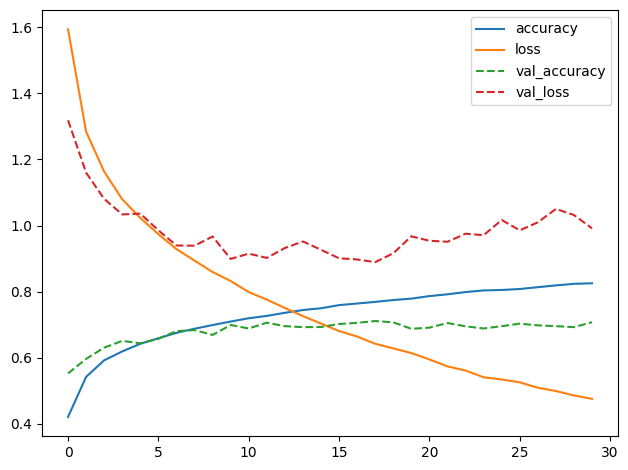

In [ ]:
show_history(history, ignore_val=False)

✍ *Vsuvka:* Loss - ztráta by měla postupně klesat k 0 📉, accuracy - přesnost by měla naopak stoupat k 1.📈

### Predikce:

In [ ]:
# Použiji testovací data které model nezná a predikuji 16 záznamů
y_pred = model.predict(X_test[:16])

# Konvertuj
y_pred_classes = probs_to_classes(y_pred)
y_pred_classes

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step


array([8, 2, 7, 2, 1, 0, 3, 9, 7, 8, 7, 7, 9, 8, 5, 5])

In [ ]:
y_test[:16]

array([[1],
       [2],
       [7],
       [8],
       [1],
       [0],
       [3],
       [1],
       [7],
       [8],
       [7],
       [7],
       [9],
       [8],
       [5],
       [7]], dtype=uint8)

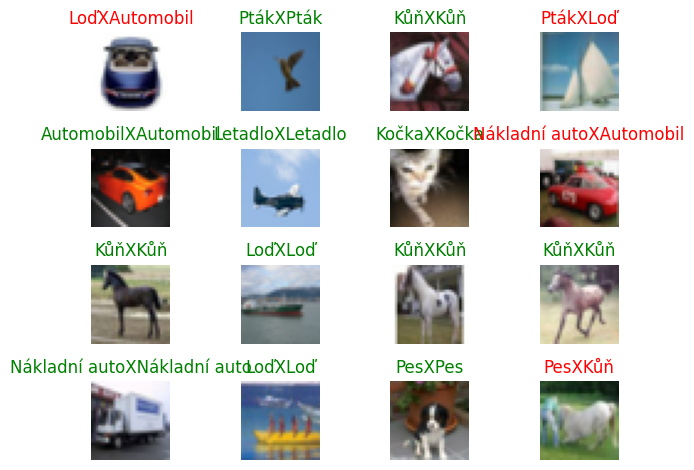

In [ ]:
for i in range(16):
    plt.subplot(4, 4, i+1)
    # Musím provést reversní reshape dat zpět na rozměr 32x32x3
    plt.imshow(X_test[i])
    pred_val = index_to_class(y_pred_classes[i], cifar10_class_dict)
    true_val = index_to_class(y_test[i][-1], cifar10_class_dict)
    # c = "b" if y_pred[i] == y_test[i] else "r" - inline ternární operátor který přepíná barvu mezi g (green) a r (red)
    plt.title(f'{pred_val}X{true_val}', c = "g" if y_pred_classes[i] == y_test[i] else "r")
    plt.axis('off')

# Zarovná layout
plt.tight_layout()

### 👁️ Pod kapotou

In [ ]:
# Function to display the grid of activations
def display_grid(data):
    num_images = data.shape[-1]
    # Calculate grid size base on num of convolution outputs
    grid_rows = grid_cols = int(np.ceil(np.sqrt(num_images)))

    # Prepare image grid
    fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(12, 12))
    axes = axes.flatten()

    # Fill grid
    for i, ax in enumerate(axes):
        if i < num_images:
            ax.imshow(data[0, :, :, i], cmap='viridis')
        ax.axis('off')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step


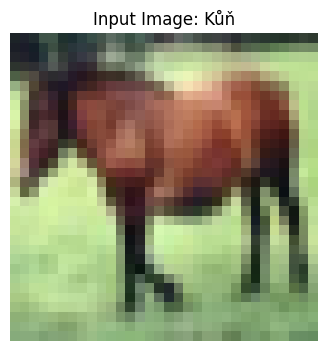

Displaying activations for layer: conv2d


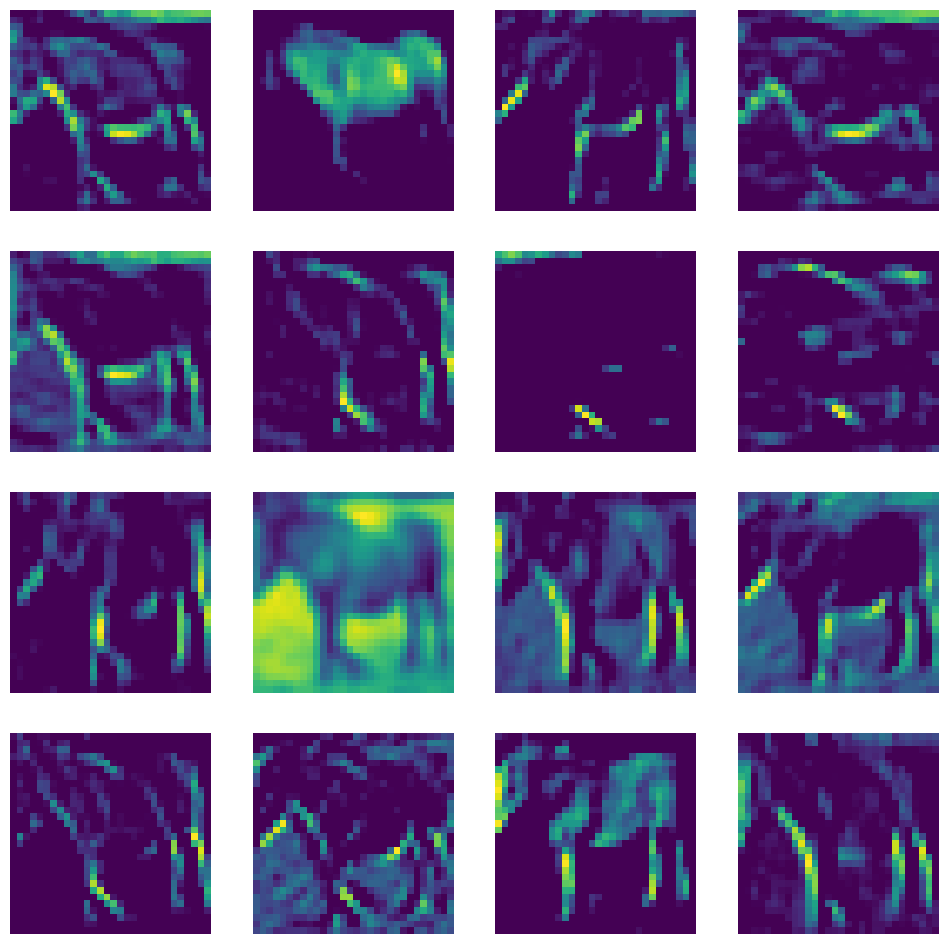

Displaying activations for layer: conv2d_1


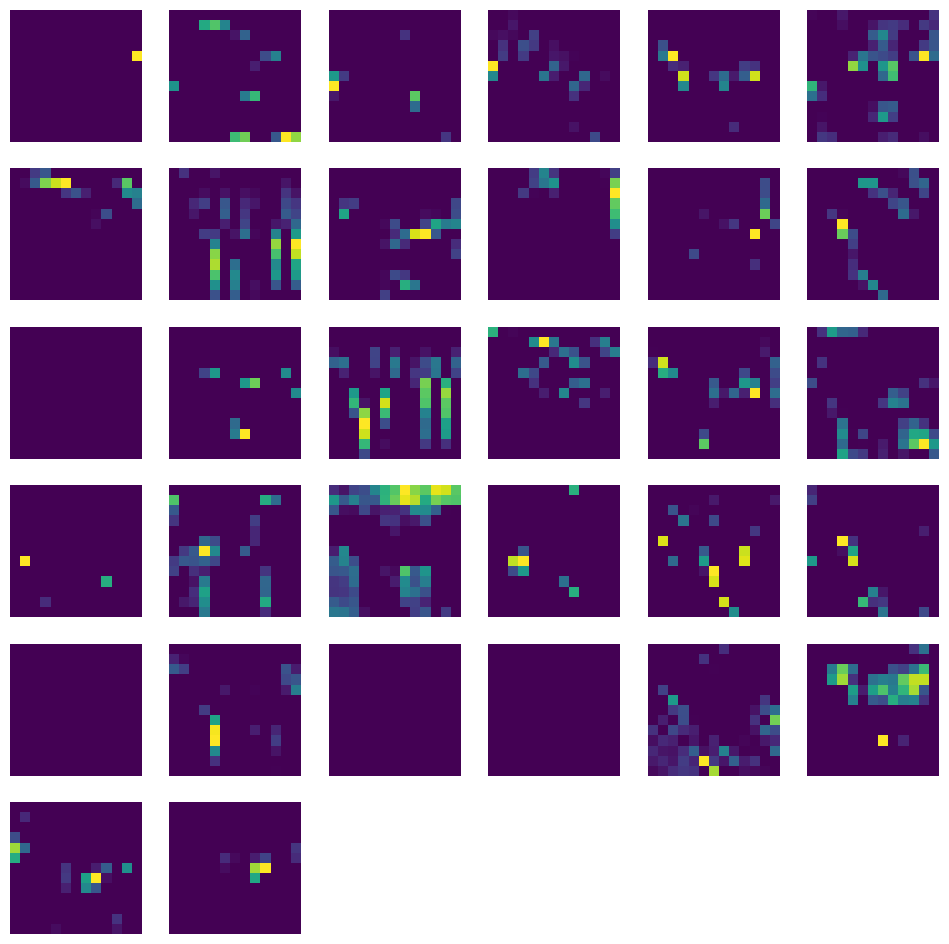

In [ ]:
# Select only convolution (conv)
# 'model' is our pre-trained CNN
layer_outputs = [layer.output for layer in model.layers if 'conv' in layer.name]
# Create dummy model from selected conv layers
activation_model = Model(inputs=model.input, outputs=layer_outputs)

# Select input image
image_index = 8
image = train_images[image_index-1:image_index]
label = index_to_class(train_labels[image_index-1][0], cifar10_class_dict)
# Pass the image through the network and get the activations
activations = activation_model.predict(image)

# Display the input image
plt.figure(figsize=(4, 4))
plt.imshow(image[0])
plt.axis('off')
plt.title(f'Input Image: {label}')
plt.show()

# Display the activations for each convolutional layer
for layer_name, layer_activation in zip([layer.name for layer in model.layers if 'conv' in layer.name], activations):
    print(f"Displaying activations for layer: {layer_name}")
    display_grid(layer_activation)

### 🧠 **ÚKOL Č. 1: Vlastní model**

- navrhněte vlastní architekturu CNN
- použijte vrstvu `BatchNormalization` (`tensorflow.keras.layers import BatchNormalization`)
- [dokumentace](https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization)
- použijte kernel regularizers: L1 a L2 [dokumentace](https://www.tensorflow.org/api_docs/python/tf/keras/Regularizer)
- otestujte síť
- **zkuste dosáhnout přesnosti (skore) 85 % a více** ❗📈



> **DORORUČUJI:**
  - zvýšit počet neuronů v konvolučních vrstvách a/nebo přidat další vrstvu
  - použít BatchNormalization
  - optimalizovat klasifikátor
  - přesnost by měla jít nahoru




In [ ]:
# Tvůj kod zde

## 🪄 **Přenesené učení**
- použijeme přístup přeneseného učení
- "*půjčíme*" si **natreénovanou konvoluční část** ze sítě `VGG19`
- dokumentace k [VGG19](https://keras.io/api/applications/vgg/)
- **klasifikátor** si natrénujeme svůj

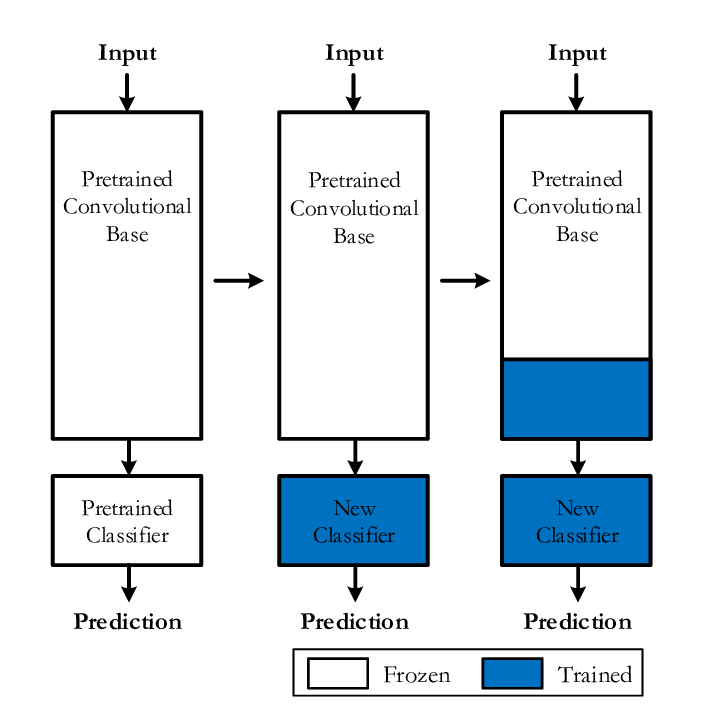

In [ ]:
from tensorflow.keras.applications import VGG19

# Načtení VGG19 modelu s předtrénovanými váhami z ImageNetu, vyloučení vrchních vrstev
base_model = VGG19(weights='imagenet', include_top=False, input_tensor=Input(shape=(32, 32, 3)))

# Zamrznutí konvolučních vrstev modelu, aby se během tréninku neaktualizovaly
# Krom poslední skupiny
for layer in base_model.layers[:-5]:
    layer.trainable = False
    print(f"Layer - {layer.name} freeze...")

# Přidání nových vrstev pro klasifikaci specifickou pro CIFAR-10
x = Flatten()(base_model.output)
x = Dense(512, activation='relu')(x)
x = Dropout(0.1)(x)
x = Dense(10, activation='softmax')(x)  # CIFAR-10 má 10 tříd

# Vytvoření nového modelu
model_vgg19 = Model(inputs=base_model.input, outputs=x)

In [ ]:
from tensorflow.keras.optimizers import Adam

# Kompilace modelu s Adam optimalizátorem a cross-entropy loss funkcí
model_vgg19.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Shrnutí modelu pro kontrolu architektury
model_vgg19.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             

 Total params: 20,292,170 (77.41 MB)

 Trainable params: 20,292,170 (77.41 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Trénování modelu

# Early Stopping callback, nastavíme trpělivost na vyšší úroveň - máme větší model
early_stopping_callback = tf.keras.callbacks.EarlyStopping(monitor='loss', min_delta=0.01, patience=5, restore_best_weights=True)

# Fit s validací a callbacky
epochs = 50
batch_size = 64
history = model_vgg19.fit(X_train, y_train, validation_data=(X_val, y_val), callbacks=[early_stopping_callback], epochs=epochs, batch_size=batch_size)

Epoch 1/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 87s 95ms/step - accuracy: 0.5784 - loss: 1.2078 - val_accuracy: 0.7660 - val_loss: 0.6878
Epoch 2/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 83ms/step - accuracy: 0.8064 - loss: 0.5750 - val_accuracy: 0.8340 - val_loss: 0.4945
Epoch 3/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 83ms/step - accuracy: 0.8594 - loss: 0.4158 - val_accuracy: 0.8335 - val_loss: 0.5266
Epoch 4/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 83ms/step - accuracy: 0.8957 - loss: 0.3157 - val_accuracy: 0.8525 - val_loss: 0.4722
Epoch 5/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 64s 82ms/step - accuracy: 0.9233 - loss: 0.2287 - val_accuracy: 0.8475 - val_loss: 0.4866
Epoch 6/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 64s 82ms/step - accuracy: 0.9387 - loss: 0.1811 - val_accuracy: 0.8505 - val_loss: 0.5172
Epoch 7/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 82ms/step - accuracy: 0.9555 - loss: 0.1320 - val_accuracy: 0.8425 - val_loss: 0.5547
Epoch 8/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 83ms/step - accuracy: 0.9664 - loss: 0.1050 - 

250/250 [==============================] - 3s 10ms/step - loss: 1.0863 - accuracy: 0.6198


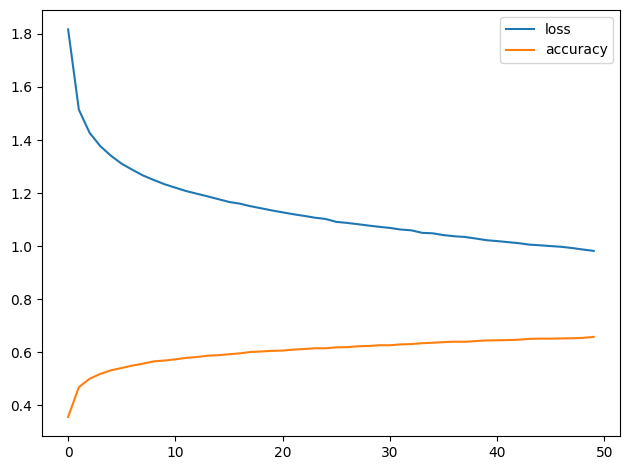

In [ ]:
# Vyhodnocení přesnosti modelu
model_vgg19.evaluate(X_test, y_test)
show_history(history)

✍ *Vsuvka:* Jak vidíte, náš primitivní model si zde vedl lépe než VGG-19. Je to tím že konvoluční část je až moc obecná.

###  🧠 **ÚKOL Č. 2: Přenesené učení**

- využijte poznatky o přeneseném učení
- navrhněte vlastní složený model
- otestujte


> **DOPORUČENÍ:**
Postupujte stejně jako jsem postpoval výše, ALE, neprovádějte zmražení poslední konvoluční části VGG19.

❄️Zmržení se dělá v této části kodu:
```
for layer in base_model.layers[:-4]:
    layer.trainable = False
```








In [ ]:
# Tvůj kod zde